# **Master notebook — Trelew IRIS, 11 March 2015: all paper figures**

> ***Note:** Data preprocessing and author rights - P. González-Soto*
> ***Note:** Experimental analysis - J. Saavedra-Bastidas*

Merged from `V12_10Plots_Paper_Pedro.ipynb` and `V12_10PCA_Variants.ipynb`. Run the cells **in order, top to bottom** (Runtime → Run all).

| Section | Output | Status |
|---|---|---|
| 0. Setup | paths, thresholds, style | — |
| 1. Data | `filtered_df` (0.25–2.0 dB) | unchanged |
| 2. Figure 1 | CNA + GOES-13 X-ray flux | unchanged |
| 3. Trustworthiness stack | 2 × 3 panels | unchanged |
| 4. 3D projections | 2 × 3 panels | panel order (e) cosine, (f) sigmoid |
| 5. DBSCAN hyperparameter selection | Silhouette & Calinski–Harabasz sweeps (support) | same sweeps as before |
| 6. DBSCAN clustering | 3 figures × 2 methods | **adds precision and F1** |
| 7. Tables | metrics table (LaTeX + CSV) | new |

**Hyperparameters are not changed anywhere.** All figures and tables are written to the folder `figures_master/`.

**Files needed** (upload to Colab's `/content` or run the upload cell): `images1103_TRW.csv`, `g13_xrs_1m_20150301_20150331.csv`.

## **0. Setup**

In [ ]:
# ==========================================================
# 0.1 MODULES
# ==========================================================
import os
import re
import zipfile

import numpy             as np
import pandas            as pd
import matplotlib.pyplot as plt

from matplotlib        import cm
from matplotlib.ticker import MaxNLocator, FuncFormatter

from sklearn.cluster         import DBSCAN
from sklearn.metrics         import silhouette_score, calinski_harabasz_score
from sklearn.model_selection import train_test_split
from sklearn.manifold        import trustworthiness
from sklearn.decomposition   import PCA, KernelPCA, IncrementalPCA
from sklearn.preprocessing   import StandardScaler

# ==========================================================
# 0.2 CONFIGURATION (single place for every fixed value)
# ==========================================================
PATH_CNA  = "images1103_TRW.csv"
PATH_GOES = "g13_xrs_1m_20150301_20150331.csv"

# Data-selection thresholds on the beam-averaged CNA [dB]
CNA_LOWER = 0.25
CNA_UPPER = 2.0

# Flare interval (row index of the CSV): 14600–15000 = 16:13–16:40 UTC
EVENT_ID_START = 14600
EVENT_ID_END   = 15000

# Train/test split used by the trustworthiness and 3D figures
TEST_SIZE    = 0.4
RANDOM_STATE = 42

# Output folder for every figure and table
OUTDIR = "figures_master"
os.makedirs(OUTDIR, exist_ok=True)

def out(name):
    return os.path.join(OUTDIR, name)

# ==========================================================
# 0.3 SHARED FIGURE STYLE (same as the revised figures)
# ==========================================================
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 15,
    "axes.titlesize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 11,
    "axes.linewidth": 1.0,
    "savefig.dpi": 600
})

# Same panel-letter style in every figure
PANEL_KW = dict(fontsize=14, fontweight='normal')

In [ ]:
# ==========================================================
# 0.4 INPUT FILES (uploads them in Colab if missing)
# ==========================================================
missing = [p for p in (PATH_CNA, PATH_GOES) if not os.path.exists(p)]

if missing:
    try:
        from google.colab import files
        print("Missing:", missing, "-> select them in the upload dialog")
        files.upload()
    except ImportError:
        raise FileNotFoundError(
            f"Missing input files: {missing}. Put them next to this notebook."
        )

for p in (PATH_CNA, PATH_GOES):
    print(f"{p}: {'OK' if os.path.exists(p) else 'NOT FOUND'}")

images1103_TRW.csv: OK
g13_xrs_1m_20150301_20150331.csv: OK


## **1. Data preparation**

Same preprocessing as both original notebooks: real part of the beam values, columns renamed `Beam 1 … Beam 16`, and rows kept when the beam-averaged CNA is between `CNA_LOWER` and `CNA_UPPER`.

In [ ]:
# Import the data
df_images = pd.read_csv(PATH_CNA).drop(['Unnamed: 0'], axis=1)

# List of columns containing complex values
complex_columns = df_images.columns[1:]

# Iterate over the complex columns and replace complex values with their real parts
for col in complex_columns:
    df_images[col] = df_images[col].apply(
        lambda x: x if isinstance(x, float)
        else float(re.search(r'(-?\d+\.\d+)', str(x)).group())
    )

# Rename columns for convenience
mapp_cols = {f"pix_{i}": f"Beam {i}" for i in range(1, 17)}
df_images = df_images.rename(columns=mapp_cols)

# Calculate the mean for each row (excluding the 'TIME' column)
row_means = df_images.iloc[:, 1:].mean(axis=1)

# Apply the filter based on the mean values
filter_condition = (row_means >= CNA_LOWER) & (row_means <= CNA_UPPER)
filtered_df      = df_images[filter_condition].drop(columns="TIME (INT)")

# Event mask on the filtered data (index = original row number)
ids_all      = filtered_df.index.values
event_mask   = (ids_all >= EVENT_ID_START) & (ids_all <= EVENT_ID_END)
N_TOTAL      = len(filtered_df)
N_EVENT      = int(event_mask.sum())
N_OTHER      = N_TOTAL - N_EVENT
BASE_RATE    = N_EVENT / N_TOTAL

print(f"Raw samples:            {len(df_images)}")
print(f"Filtered samples:       {N_TOTAL}  ({CNA_LOWER}–{CNA_UPPER} dB)")
print(f"  flare interval:       {N_EVENT}")
print(f"  other measurements:   {N_OTHER}")
print(f"Event share (precision of a random grouping): {100*BASE_RATE:.2f}%")
display(filtered_df.head())

Raw samples:            21600
Filtered samples:       204  (0.25–2.0 dB)
  flare interval:       121
  other measurements:   83
Event share (precision of a random grouping): 59.31%


,Beam 1,Beam 2,Beam 3,Beam 4,Beam 5,Beam 6,Beam 7,Beam 8,Beam 9,Beam 10,Beam 11,Beam 12,Beam 13,Beam 14,Beam 15,Beam 16
14679,0.589711,0.369588,0.321003,0.283338,0.168117,0.179233,0.213009,0.255335,0.364918,0.221762,0.194769,0.456180,0.298472,0.303012,0.437676,0.471232
14680,0.638276,0.439781,0.338726,0.279597,0.118653,0.200384,0.210288,0.269222,0.835204,0.466962,0.274102,0.500560,0.392095,0.385905,0.434089,0.533813
14684,0.540032,0.453682,0.410989,0.531500,0.034561,0.335193,0.331828,0.457146,0.497895,0.329373,0.431033,0.790034,0.352003,0.597002,0.633683,0.780838
14685,0.807003,0.500760,0.559091,0.583252,0.422241,0.308249,0.329172,0.453040,0.652032,0.452414,0.515499,0.731559,0.574861,0.571734,0.643112,0.834345
14686,0.746810,0.448619,0.578366,0.664040,0.346244,0.305776,0.371531,0.545263,0.648237,0.323686,0.424533,0.833620,0.494241,0.614633,0.678610,0.933053


## **2. Figure 1 — CNA and GOES-13 X-ray flux**

Unchanged from `V12_10Plots_Paper_Pedro.ipynb` (only file paths and the output folder are taken from the configuration).

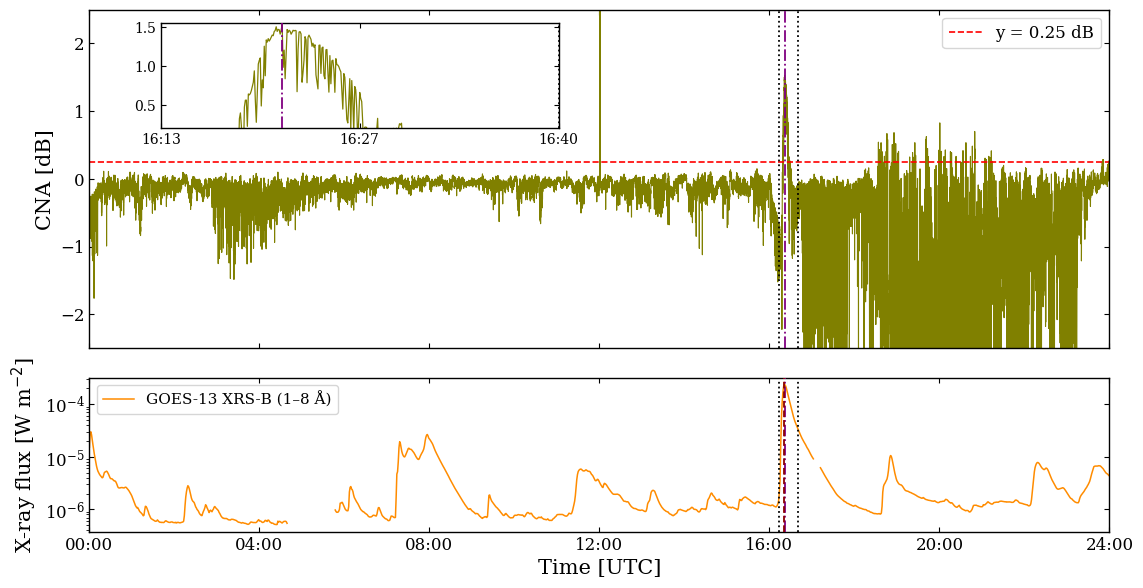

FIGURE 1 — EVENT INFORMATION
Start: timestamp 14600 = 16:13 UTC
End: timestamp 15000 = 16:40 UTC
CNA peak: timestamp 14722 = 16:21 UTC
Maximum CNA: 1.5296 dB
GOES peak: 16:21 UTC
Maximum GOES XRS-B flux: 2.3500e-04 W/m²


In [ ]:
# ==========================================================
# FIGURE 1 — TRW CNA + GOES-13 X-RAY FLUX
# 11 MARCH 2015
#
# Panel (a): Mean CNA from 16 beams + inset
# Panel (b): GOES-13 XRS-B (1–8 Å)
#
# Original inset: timestamps 14600–15000
# ==========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from pathlib import Path

# ==========================================================
# 1. FILE PATHS
# ==========================================================

path_cna = PATH_CNA
path_goes = PATH_GOES

# ==========================================================
# 2. LOAD CNA DATA
# ==========================================================

df_fig1 = pd.read_csv(path_cna)

df_fig1 = df_fig1.drop(
    columns=["Unnamed: 0"],
    errors="ignore"
)

# Select the 16 beams
beam_cols = [
    col for col in df_fig1.columns
    if col.startswith("pix_")
]

# Convert complex/string values to real numbers
for col in beam_cols:
    df_fig1[col] = (
        df_fig1[col]
        .astype(str)
        .str.extract(
            r'([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)'
        )[0]
    )
    df_fig1[col] = pd.to_numeric(
        df_fig1[col], errors="coerce"
    )

# Original mean CNA calculation
mean_df = df_fig1[beam_cols].mean(
    axis=1
).to_frame("Mean")

# Preserve the original plot index (0–21599)
timestamp = np.arange(len(mean_df))
cna = mean_df["Mean"].to_numpy()

# ==========================================================
# 3. CONVERT TIMESTAMP TO UTC
# ==========================================================

# Assumption: 21600 samples = 24 hours
samples_per_day = 21600

utc_hours = timestamp * 24.0 / samples_per_day

def format_utc(x, pos=None):
    """Convert decimal hours to HH:MM UTC."""
    total_minutes = int(round(x * 60))
    hh, mm = divmod(total_minutes, 60)
    return f"{hh:02d}:{mm:02d}"

# ==========================================================
# 4. ORIGINAL EVENT INTERVAL
# ==========================================================

timestamp_start = EVENT_ID_START
timestamp_end = EVENT_ID_END

t_start = timestamp_start * 24 / samples_per_day
t_end = timestamp_end * 24 / samples_per_day

# Maximum CNA inside original interval
event_mask = (
    (timestamp >= timestamp_start)
    & (timestamp <= timestamp_end)
    & np.isfinite(cna)
)

event_indices = np.where(event_mask)[0]

if len(event_indices) == 0:
    raise ValueError("No valid CNA data in event interval.")

peak_idx = event_indices[
    np.argmax(cna[event_indices])
]

t_peak_cna = utc_hours[peak_idx]
peak_cna = cna[peak_idx]

# ==========================================================
# 5. LOAD GOES-13 X-RAY DATA
# ==========================================================

# Find the actual data header automatically
with open(path_goes, "r", encoding="utf-8") as f:
    lines = f.readlines()

header_idx = next(
    i for i, line in enumerate(lines)
    if line.startswith("time_tag,A_QUAL_FLAG")
)

goes = pd.read_csv(
    path_goes,
    skiprows=header_idx,
    skipinitialspace=True
)

goes["time_tag"] = pd.to_datetime(
    goes["time_tag"], utc=True
)

# Select March 11, 2015
date_start = pd.Timestamp(
    "2015-03-11", tz="UTC"
)
date_end = date_start + pd.Timedelta(days=1)

goes = goes[
    (goes["time_tag"] >= date_start)
    & (goes["time_tag"] < date_end)
].copy()

# Use valid GOES XRS-B observations
goes["B_AVG"] = pd.to_numeric(
    goes["B_AVG"], errors="coerce"
)

goes.loc[
    (goes["B_QUAL_FLAG"] != 0)
    | (goes["B_AVG"] <= 0)
    | (goes["B_AVG"] <= -99999),
    "B_AVG"
] = np.nan

goes["UTC_hour"] = (
    goes["time_tag"].dt.hour
    + goes["time_tag"].dt.minute / 60
    + goes["time_tag"].dt.second / 3600
)

# Maximum GOES flux inside the same interval
goes_event = goes[
    (goes["UTC_hour"] >= t_start)
    & (goes["UTC_hour"] <= t_end)
].dropna(subset=["B_AVG"])

if goes_event.empty:
    raise ValueError("No valid GOES data in event interval.")

goes_peak_idx = goes_event["B_AVG"].idxmax()

t_peak_goes = goes_event.loc[
    goes_peak_idx, "UTC_hour"
]

peak_goes = goes_event.loc[
    goes_peak_idx, "B_AVG"
]

# ==========================================================
# 6. FIGURE STYLE
# ==========================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 15,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 11,
    "axes.linewidth": 1.0,
    "savefig.dpi": 600
})

fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(12, 6),
    sharex=True,
    gridspec_kw={
        "height_ratios": [2.2, 1],
        "hspace": 0.12
    }
)

# ==========================================================
# 7. PANEL (a): CNA
# ==========================================================

ax1.plot(
    utc_hours,
    cna,
    color="olive",
    lw=0.8
)

ax1.set_ylabel("CNA [dB]")
ax1.set_ylim(-2.5, 2.5)

# Original horizontal thresholds
ax1.axhline(
    y=0.25,
    color="red",
    linestyle="--",
    linewidth=1.2,
    label="y = 0.25 dB"
)

#ax1.axhline(
#    y=2.0,
#    color="green",
#    linestyle="--",
#    linewidth=1.2,
#    label="y = 2.00 dB"
#)
ax1.legend(
    loc="upper right",
    fontsize=12,
    frameon=True
)

# Panel label
#ax1.text(
#    0.01, 0.93,
#    "(a)",
#    transform=ax1.transAxes,
#    fontsize=10,
#    fontweight="bold"
#)

# ==========================================================
# 8. CNA INSET
# ==========================================================

inset = ax1.inset_axes(
    [0.07, 0.65, 0.39, 0.31]
)

inset.plot(
    utc_hours,
    cna,
    color="olive",
    lw=0.9
)

# Preserve original timestamp range
inset.set_xlim(t_start, t_end)
inset.set_ylim(0.20, 1.55)

# Show UTC instead of timestamp
inset.set_xticks([
    t_start,
    (t_start + t_end) / 2,
    t_end
])

inset.xaxis.set_major_formatter(
    FuncFormatter(format_utc)
)

inset.tick_params(
    axis="both",
    labelsize=10
)

# ==========================================================
# 9. PANEL (b): GOES X-RAY FLUX
# ==========================================================

ax2.plot(
    goes["UTC_hour"],
    goes["B_AVG"],
    color="darkorange",
    lw=1.1,
    label="GOES-13 XRS-B (1–8 Å)"
)

ax2.set_yscale("log")

ax2.set_ylabel(
    r"X-ray flux [W m$^{-2}$]"
)

ax2.set_xlabel("Time [UTC]")

ax2.legend(
    loc="upper left",
    fontsize=11
)

#ax2.text(
#    0.01, 0.88,
#    "(b)",
#    transform=ax2.transAxes,
#    fontsize=10,
#    fontweight="bold"
#)

# ==========================================================
# 10. VERTICAL EVENT LINES
# ==========================================================

# Same CNA-based event markers in both panels
# and in the inset.

for ax in [ax1, ax2, inset]:

    # Event start
    ax.axvline(
        t_start,
        color="black",
        linestyle=":",
        linewidth=1.3,
        zorder=4
    )

    # Event end
    ax.axvline(
        t_end,
        color="black",
        linestyle=":",
        linewidth=1.3,
        zorder=4
    )

    # Maximum CNA
    ax.axvline(
        t_peak_cna,
        color="purple",
        linestyle="-.",
        linewidth=1.3,
        zorder=5
    )

# Mark GOES maximum separately in panel (b)
ax2.axvline(
    t_peak_goes,
    color="darkred",
    linestyle="--",
    linewidth=1.3,
    zorder=5
)

# ==========================================================
# 11. UTC AXIS FORMAT
# ==========================================================

ax2.set_xlim(0, 24)

ax2.set_xticks(
    np.arange(0, 25, 4)
)

ax2.xaxis.set_major_formatter(
    FuncFormatter(format_utc)
)

ax1.tick_params(
    axis="both",
    direction="in",
    top=True,
    right=True
)

ax2.tick_params(
    axis="both",
    direction="in",
    top=True,
    right=True
)

inset.tick_params(
    axis="both",
    direction="in",
    top=True,
    right=True
)

# ==========================================================
# 12. SAVE FIGURE
# ==========================================================

fig.subplots_adjust(
    left=0.12,
    right=0.97,
    bottom=0.10,
    top=0.97
)

plt.savefig(
    out("Figure_1_TRW_GOES_revised.png"),
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    out("Figure_1_TRW_GOES_revised.pdf"),
    bbox_inches="tight"
)

plt.show()

# ==========================================================
# 13. PRINT EVENT INFORMATION
# ==========================================================

print("=" * 55)
print("FIGURE 1 — EVENT INFORMATION")
print("=" * 55)

print(
    f"Start: timestamp {timestamp_start} "
    f"= {format_utc(t_start)} UTC"
)

print(
    f"End: timestamp {timestamp_end} "
    f"= {format_utc(t_end)} UTC"
)

print(
    f"CNA peak: timestamp {peak_idx} "
    f"= {format_utc(t_peak_cna)} UTC"
)

print(f"Maximum CNA: {peak_cna:.4f} dB")

print(
    f"GOES peak: {format_utc(t_peak_goes)} UTC"
)

print(
    f"Maximum GOES XRS-B flux: "
    f"{peak_goes:.4e} W/m²"
)

print("=" * 55)

## **3. Trustworthiness vs number of components**

Unchanged from `V12_10Plots_Paper_Pedro.ipynb` (2 × 3 panels; shared axis labels and title).

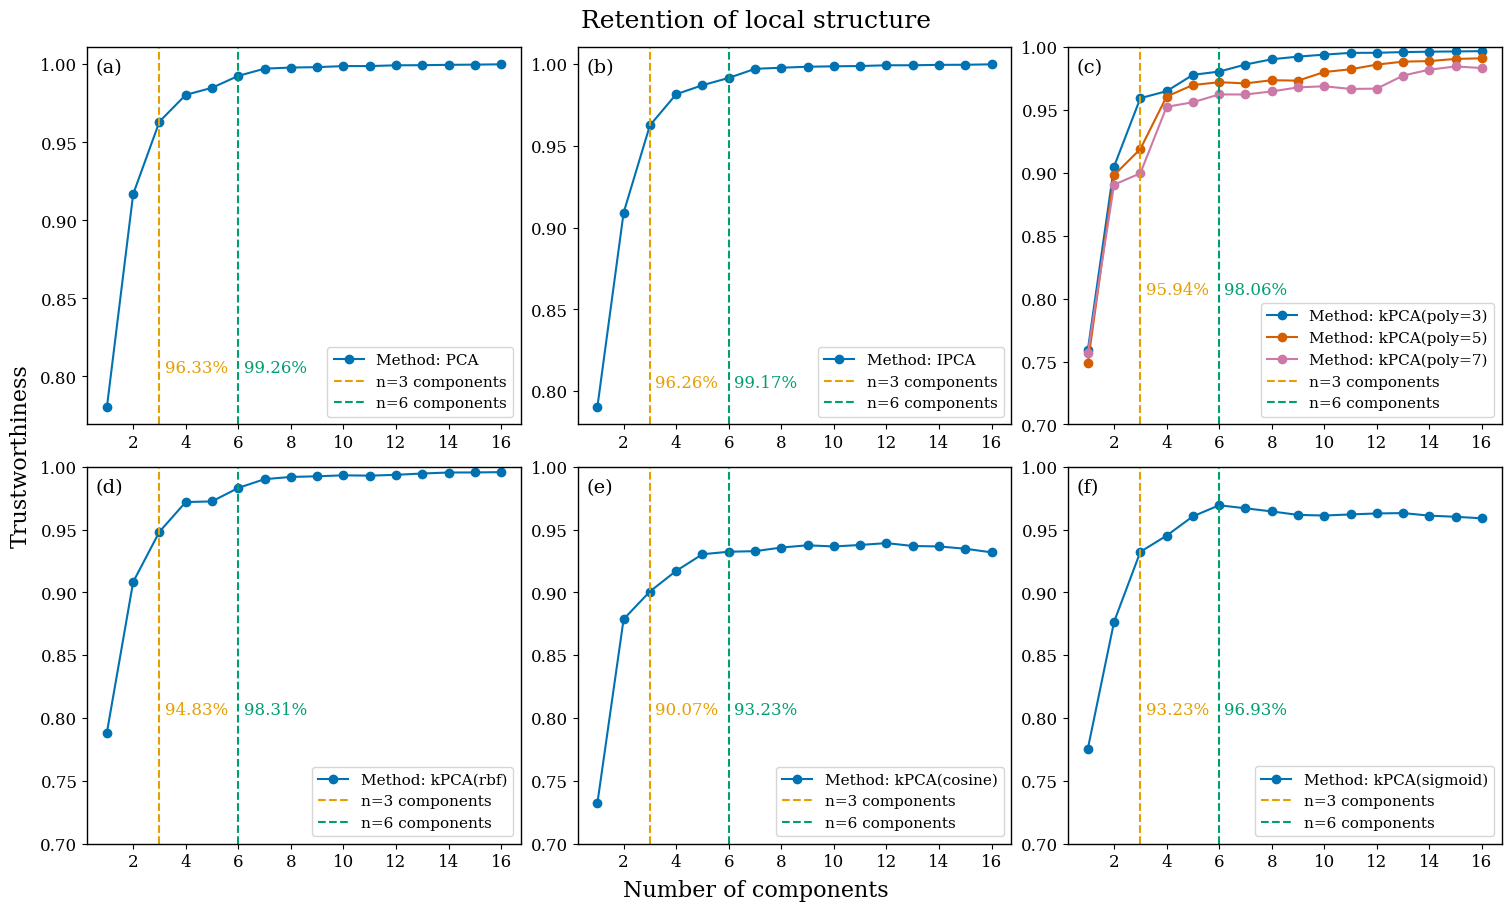

In [ ]:
# ==========================================================
# FIGURES 2–7 — COMBINED TRUSTWORTHINESS
# 2 ROWS × 3 COLUMNS
# SAME DIMENSIONS AS FIGURE 8
# ==========================================================

# ==========================================================
# 1. IMPORT LIBRARIES
# ==========================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.decomposition import (
    PCA,
    IncrementalPCA,
    KernelPCA
)
from sklearn.manifold import trustworthiness

# ==========================================================
# 2. PREPARE DATA
# ==========================================================

df_train, df_test = train_test_split(
    filtered_df,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

n_components = range(
    1, len(filtered_df.columns) + 1
)

# ==========================================================
# 3. PCA
# ==========================================================

metric_pca = []

for n in n_components:

    pca = PCA(n_components=n)

    x_emb = pca.fit_transform(df_train)

    metric_pca.append(
        trustworthiness(
            X=df_train.to_numpy(),
            X_embedded=x_emb
        )
    )

# ==========================================================
# 4. INCREMENTAL PCA
# ==========================================================

metric_ipca = []

for n in n_components:

    ipca = IncrementalPCA(n_components=n)

    x_emb = ipca.fit_transform(df_train)

    metric_ipca.append(
        trustworthiness(
            X=df_train.to_numpy(),
            X_embedded=x_emb
        )
    )

# ==========================================================
# 5. KERNEL PCA — POLYNOMIAL DEGREE 3
# ==========================================================

metric_poly3 = []

for n in n_components:

    kpca = KernelPCA(
        n_components=n,
        kernel="poly",
        degree=3
    )

    x_emb = kpca.fit_transform(df_train)

    metric_poly3.append(
        trustworthiness(
            X=df_train.to_numpy(),
            X_embedded=x_emb
        )
    )

# ==========================================================
# 6. KERNEL PCA — POLYNOMIAL DEGREE 5
# ==========================================================

metric_poly5 = []

for n in n_components:

    kpca = KernelPCA(
        n_components=n,
        kernel="poly",
        degree=5
    )

    x_emb = kpca.fit_transform(df_train)

    metric_poly5.append(
        trustworthiness(
            X=df_train.to_numpy(),
            X_embedded=x_emb
        )
    )

# ==========================================================
# 7. KERNEL PCA — POLYNOMIAL DEGREE 7
# ==========================================================

metric_poly7 = []

for n in n_components:

    kpca = KernelPCA(
        n_components=n,
        kernel="poly",
        degree=7
    )

    x_emb = kpca.fit_transform(df_train)

    metric_poly7.append(
        trustworthiness(
            X=df_train.to_numpy(),
            X_embedded=x_emb
        )
    )

# ==========================================================
# 8. KERNEL PCA — RBF
# ==========================================================

metric_rbf = []

for n in n_components:

    kpca = KernelPCA(
        n_components=n,
        kernel="rbf"
    )

    x_emb = kpca.fit_transform(df_train)

    metric_rbf.append(
        trustworthiness(
            X=df_train.to_numpy(),
            X_embedded=x_emb
        )
    )

# ==========================================================
# 9. KERNEL PCA — COSINE
# ==========================================================

metric_cosine = []

for n in n_components:

    kpca = KernelPCA(
        n_components=n,
        kernel="cosine"
    )

    x_emb = kpca.fit_transform(df_train)

    metric_cosine.append(
        trustworthiness(
            X=df_train.to_numpy(),
            X_embedded=x_emb
        )
    )

# ==========================================================
# 10. KERNEL PCA — SIGMOID
# ==========================================================

metric_sigmoid = []

for n in n_components:

    kpca = KernelPCA(
        n_components=n,
        kernel="sigmoid"
    )

    x_emb = kpca.fit_transform(df_train)

    metric_sigmoid.append(
        trustworthiness(
            X=df_train.to_numpy(),
            X_embedded=x_emb
        )
    )

# ==========================================================
# 11. CREATE FIGURE
# ==========================================================

# Same dimensions as Figure 8
fig = plt.figure(figsize=(15, 9), layout='constrained')

# ==========================================================
# 12. PLOTTING FUNCTION
# ==========================================================

def plot_trustworthiness(
    ax,
    curves,
    labels,
    colors,
    annotation_metric,
    ylim=None
):

    # Plot curves
    for values, label, color in zip(
        curves, labels, colors
    ):

        ax.plot(
            n_components,
            values,
            c=color,
            marker='o',
            label=label
        )

    # Vertical line at 3 components
    ax.axvline(
        x=3,
        color='#E69F00',
        linestyle='--',
        label='n=3 components'
    )

    # Vertical line at 6 components
    ax.axvline(
        x=6,
        color='#009E73',
        linestyle='--',
        label='n=6 components'
    )

    # Original annotations
    ax.text(
        3.2,
        0.8,
        f'{annotation_metric[2]*100:.2f}%',
        verticalalignment='bottom',
        color='#E69F00'
    )

    ax.text(
        6.2,
        0.8,
        f'{annotation_metric[5]*100:.2f}%',
        verticalalignment='bottom',
        color='#009E73'
    )

    # Preserve original Y-axis limits
    if ylim is not None:
        ax.set_ylim(ylim)

    # Integer ticks only on the x axis
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))

    # (repetitive setting) Original labels and title
    #ax.set_xlabel('Number of Components')
    #ax.set_ylabel('Trustworthiness')
    #ax.set_title('Retention of local structure')

    # Original legend
    ax.legend(loc='best')


# ==========================================================
# 13. PANEL CONFIGURATION
# ==========================================================

data_list = [

    # Figure 2 — PCA
    (
        [metric_pca],
        ['Method: PCA'],
        ['#0072B2'],
        metric_pca,
        None
    ),

    # Figure 3 — Incremental PCA
    (
        [metric_ipca],
        ['Method: IPCA'],
        ['#0072B2'],
        metric_ipca,
        None
    ),

    # Figure 4 — Polynomial Kernel PCA
    (
        [
            metric_poly3,
            metric_poly5,
            metric_poly7
        ],
        [
            'Method: kPCA(poly=3)',
            'Method: kPCA(poly=5)',
            'Method: kPCA(poly=7)'
        ],
        [
            '#0072B2',
            '#D55E00',
            '#CC79A7'
        ],
        metric_poly3,
        [0.7, 1.00]
    ),

    # Figure 5 — RBF Kernel PCA
    (
        [metric_rbf],
        ['Method: kPCA(rbf)'],
        ['#0072B2'],
        metric_rbf,
        [0.7, 1.00]
    ),

    # Figure 6 — Cosine Kernel PCA
    (
        [metric_cosine],
        ['Method: kPCA(cosine)'],
        ['#0072B2'],
        metric_cosine,
        [0.7, 1.00]
    ),

    # Figure 7 — Sigmoid Kernel PCA
    (
        [metric_sigmoid],
        ['Method: kPCA(sigmoid)'],
        ['#0072B2'],
        metric_sigmoid,
        [0.7, 1.00]
    )
]

# ==========================================================
# 14. PLOT SIX PANELS
# ==========================================================

for i, (
    curves,
    labels,
    colors,
    annotation_metric,
    ylim
) in enumerate(data_list, 1):

    # Same 2 × 3 layout as Figure 8
    ax = fig.add_subplot(2, 3, i)

    plot_trustworthiness(
        ax=ax,
        curves=curves,
        labels=labels,
        colors=colors,
        annotation_metric=annotation_metric,
        ylim=ylim
    )
    ax.text(
        0.02, 0.97,
        f'({"abcdef"[i-1]})',
        transform=ax.transAxes,
        fontsize=14,
        fontweight='normal',
        va='top'
    )

# ==========================================================
# 15. SAVE FIGURE
# ==========================================================

fig.supxlabel('Number of components', fontsize=16)
fig.supylabel('Trustworthiness', fontsize=16)
fig.suptitle('Retention of local structure', fontsize=18)

plt.savefig(
    out('1103_TRW_combined_trustworthiness.png'),
    dpi=600,
    bbox_inches='tight'
)

plt.show()

## **4. PCA / kernel PCA visualization: 3D projections**

From `V12_10PCA_Variants.ipynb`: models fitted on the training set and applied to the test set (same split as Section 3).

Only change: the last two panels are **(e) cosine, (f) sigmoid**, the same order as the trustworthiness and DBSCAN figures and as the caption.

In [ ]:
# Select train, test split data
df_train, df_test = train_test_split(filtered_df, test_size=TEST_SIZE, random_state=RANDOM_STATE)

pca      = PCA(n_components = 3)
inc_pca  = IncrementalPCA( n_components=3)
kpca_pol = KernelPCA( n_components=3, kernel="poly",degree=3)
kpca_rbf = KernelPCA( n_components=3, kernel="rbf")
kpca_sig = KernelPCA( n_components=3, kernel="sigmoid")
kpca_cos = KernelPCA( n_components=3, kernel="cosine")

df_test_pca         = pca.fit(df_train).transform(df_test)
df_test_inc_pca     = inc_pca.fit(df_train).transform(df_test)
df_test_kpca_poly   = kpca_pol.fit(df_train).transform(df_test)
df_test_kpca_rbf    = kpca_rbf.fit(df_train).transform(df_test)
df_test_kpca_sig    = kpca_sig.fit(df_train).transform(df_test)
df_test_kpca_cos    = kpca_cos.fit(df_train).transform(df_test)

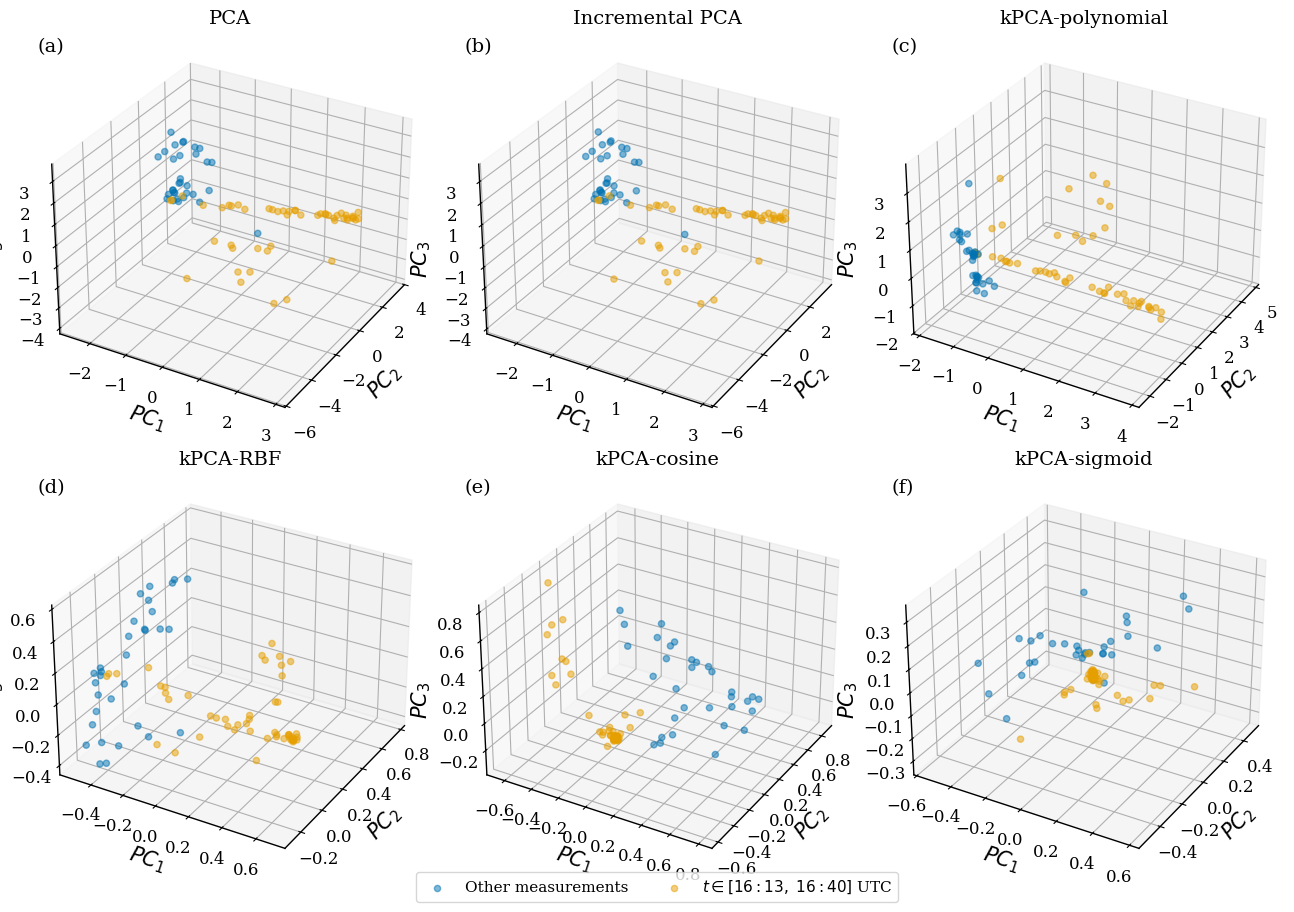

In [ ]:
# ==========================================================
# SHARED FIGURE STYLE (same as Figure 1)
# ==========================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 15,
    "axes.titlesize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 11,
    "axes.linewidth": 1.0,
    "savefig.dpi": 600
})

# Same panel-letter style in every figure
PANEL_KW = dict(fontsize=14, fontweight='normal')

# ==========================================================
# 3D PROJECTIONS
# ==========================================================

# Create a mask to identify points in the range of interest
mask = (df_test.index >= EVENT_ID_START) & (df_test.index <= EVENT_ID_END)

pc_labels = [r'$PC_1$', r'$PC_2$', r'$PC_3$']

data_list = [
    (df_test_pca,       'PCA'),
    (df_test_inc_pca,   'Incremental PCA'),
    (df_test_kpca_poly, 'kPCA-polynomial'),
    (df_test_kpca_rbf,  'kPCA-RBF'),
    (df_test_kpca_cos,  'kPCA-cosine'),
    (df_test_kpca_sig,  'kPCA-sigmoid')
]

fig = plt.figure(figsize=(15, 9))

for i, (data, title) in enumerate(data_list, 1):
    ax = fig.add_subplot(2, 3, i, projection='3d')

    ax.scatter3D(data[~mask, 0], data[~mask, 1], data[~mask, 2],
                 c="#0072B2", alpha=0.5, label='Other measurements')
    ax.scatter3D(data[mask, 0], data[mask, 1], data[mask, 2],
                 c="#E69F00", alpha=0.5, label=r'$t \in [16{:}13,\ 16{:}40]$ UTC')

    ax.set_title(title)
    ax.set_xlabel(pc_labels[0])
    ax.set_ylabel(pc_labels[1])
    ax.zaxis.set_rotate_label(False)
    ax.set_zlabel(pc_labels[2], rotation=90)

    ax.zaxis.set_ticks_position('lower')
    ax.zaxis.set_label_position('lower')
    ax.set_box_aspect(aspect=None)

    # Panel letter (a)–(f)
    ax.text2D(
        0.02, 0.95,
        f'({"abcdef"[i-1]})',
        transform=ax.transAxes,
        **PANEL_KW
    )

leg_handles, leg_labels = ax.get_legend_handles_labels()

fig.legend(
    leg_handles, leg_labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=2,
    frameon=True
)

plt.tight_layout()
plt.subplots_adjust(wspace=-0.3)
plt.savefig(out('1103_TRW_PCA_variants.jpg'), dpi=600, bbox_inches='tight')
plt.show()

## **5. DBSCAN hyperparameter selection — Silhouette and Calinski–Harabasz (support)**

Reproduces the sweeps of `V12_10PCA_Variants.ipynb` **with the same settings** (3-component projections fitted on `filtered_df`; one sweep in `eps` at fixed `min_samples`, one sweep in `min_samples` at fixed `eps`):

| Method | eps sweep | min_samples during eps sweep | eps during min_samples sweep | Notes |
|---|---|---|---|---|
| PCA | 10 values in 0.1–0.7 | 7 | 0.38 | |
| IPCA | 10 values in 0.1–0.7 | 7 | 0.43 | |
| k-PCA poly | 10 values in 0.1–0.7 | 7 | 0.43 | |
| k-PCA RBF ($\gamma$=1) | 20 values in 0.01–0.5 | 7 | 0.01 | noise points excluded in the eps sweep |
| k-PCA cosine | 10 values in 0.01–0.4 | 5 (DBSCAN default) | 0.18 | |
| k-PCA sigmoid | 10 values in 0.01–0.4 | 5 (DBSCAN default) | 0.12 | |

The grey dashed lines mark the values finally used for the 2D clustering in Section 6. These sweeps only support the choice of hyperparameters; they do not change them.

**Notes on the RBF sweep** (kept as in the original, for transparency):
- At eps = 0.01 the eps sweep finds a single non-noise cluster, so both scores are undefined (NaN). The original cell used `np.argmax`, which returns the position of a NaN, and therefore printed "optimal eps = 0.01". Here `np.nanargmax` is used, so the summary table reports the best *defined* value (≈0.04). The value used in Section 6 is still eps = 0.01.
- As in the original, the sweep projects the unscaled data, while the 2D clustering in Section 6 projects standardized data (`StandardScaler`).

In [ ]:
# ==========================================================
# 5.1 SWEEP SETTINGS (identical to the original notebook)
# ==========================================================
SWEEPS = [
    dict(name="PCA",
         model=lambda: PCA(n_components=3),
         eps_range=np.linspace(0.1, 0.7, 10), eps_min_samples=7,
         min_eps=0.38, drop_noise_eps=False),
    dict(name="Incremental PCA",
         model=lambda: IncrementalPCA(n_components=3),
         eps_range=np.linspace(0.1, 0.7, 10), eps_min_samples=7,
         min_eps=0.43, drop_noise_eps=False),
    dict(name="kPCA(poly)",
         model=lambda: KernelPCA(n_components=3, kernel="poly"),
         eps_range=np.linspace(0.1, 0.7, 10), eps_min_samples=7,
         min_eps=0.43, drop_noise_eps=False),
    dict(name="RBF kPCA",
         model=lambda: KernelPCA(n_components=3, kernel="rbf", gamma=1),
         eps_range=np.linspace(0.01, 0.5, 20), eps_min_samples=7,
         min_eps=0.01, drop_noise_eps=True),
    dict(name="kPCA(cosine)",
         model=lambda: KernelPCA(n_components=3, kernel="cosine"),
         eps_range=np.linspace(0.01, 0.4, 10), eps_min_samples=5,
         min_eps=0.18, drop_noise_eps=False),
    dict(name="kPCA(sigmoid)",
         model=lambda: KernelPCA(n_components=3, kernel="sigmoid"),
         eps_range=np.linspace(0.01, 0.4, 10), eps_min_samples=5,
         min_eps=0.12, drop_noise_eps=False),
]

MIN_RANGE = np.arange(1, 10, 1)

# Values finally used in Section 6 (shown as reference lines only)
SELECTED = {
    "PCA":             (0.40, 7),
    "Incremental PCA": (0.50, 8),
    "kPCA(poly)":      (0.43, 6),
    "RBF kPCA":        (0.01, 4),
    "kPCA(cosine)":    (0.18, 5),
    "kPCA(sigmoid)":   (0.12, 6),
}


def cluster_scores(X, labels, drop_noise=False):
    """Silhouette and Calinski–Harabasz, as in the original cells.

    As before, the noise label (-1) counts as a group unless drop_noise=True,
    and at least two groups are required. Invalid cases return NaN.
    """
    if drop_noise:
        keep = labels != -1
        X, labels = X[keep], labels[keep]
    if len(np.unique(labels)) > 1:
        try:
            return (silhouette_score(X, labels),
                    calinski_harabasz_score(X, labels))
        except ValueError:
            return np.nan, np.nan
    return np.nan, np.nan


def best_of(values, scores):
    scores = np.asarray(scores, dtype=float)
    return values[np.nanargmax(scores)] if np.any(~np.isnan(scores)) else np.nan

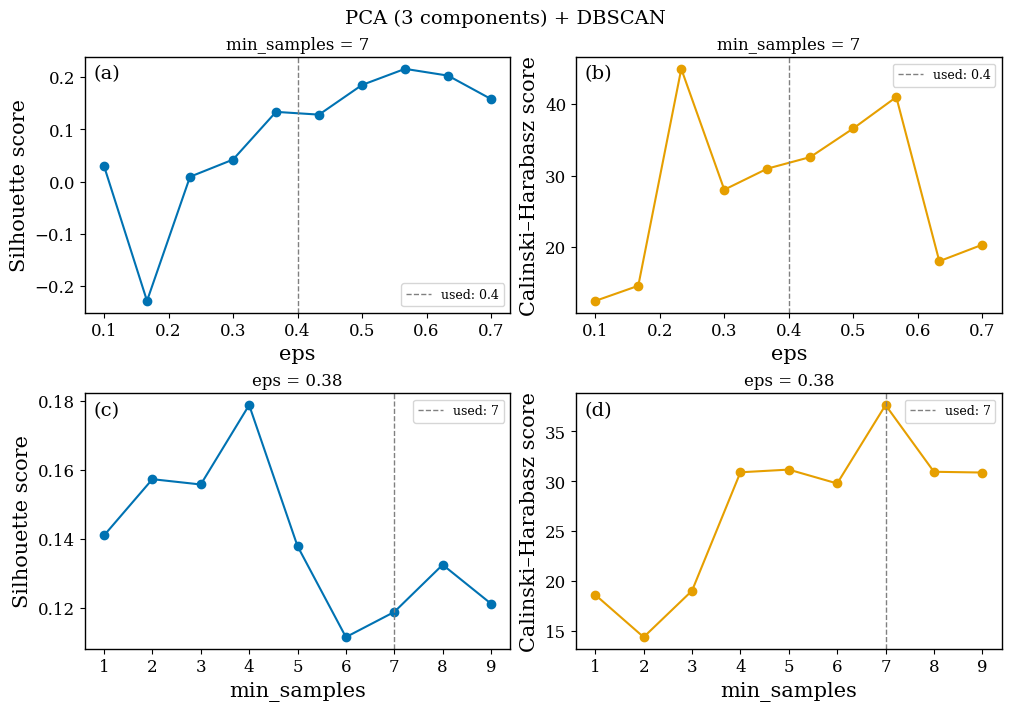

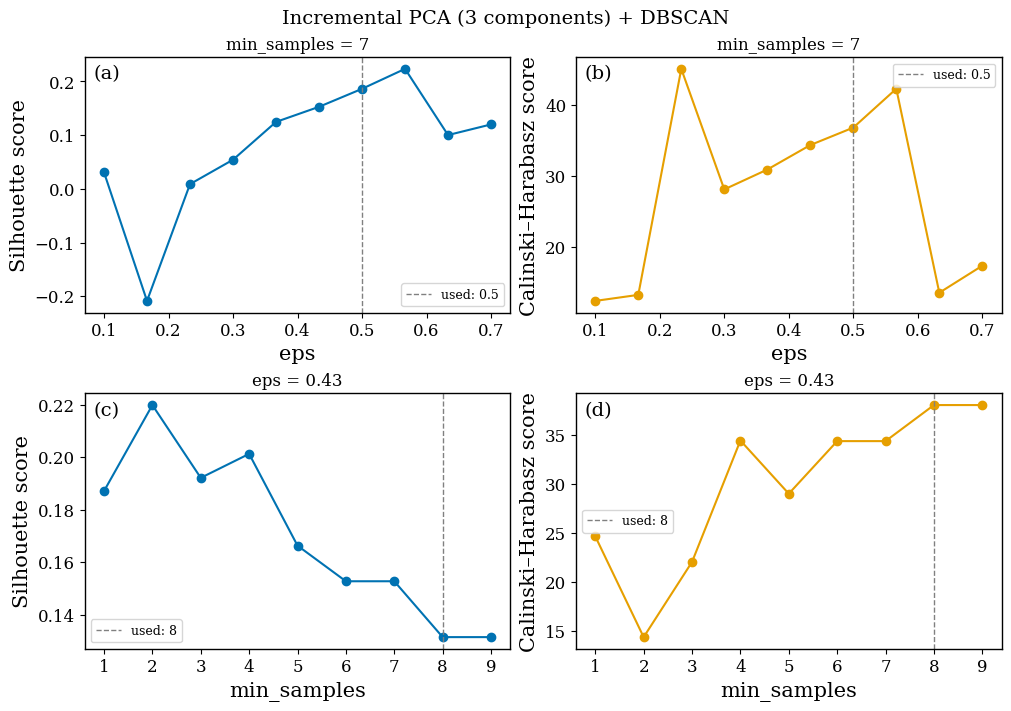

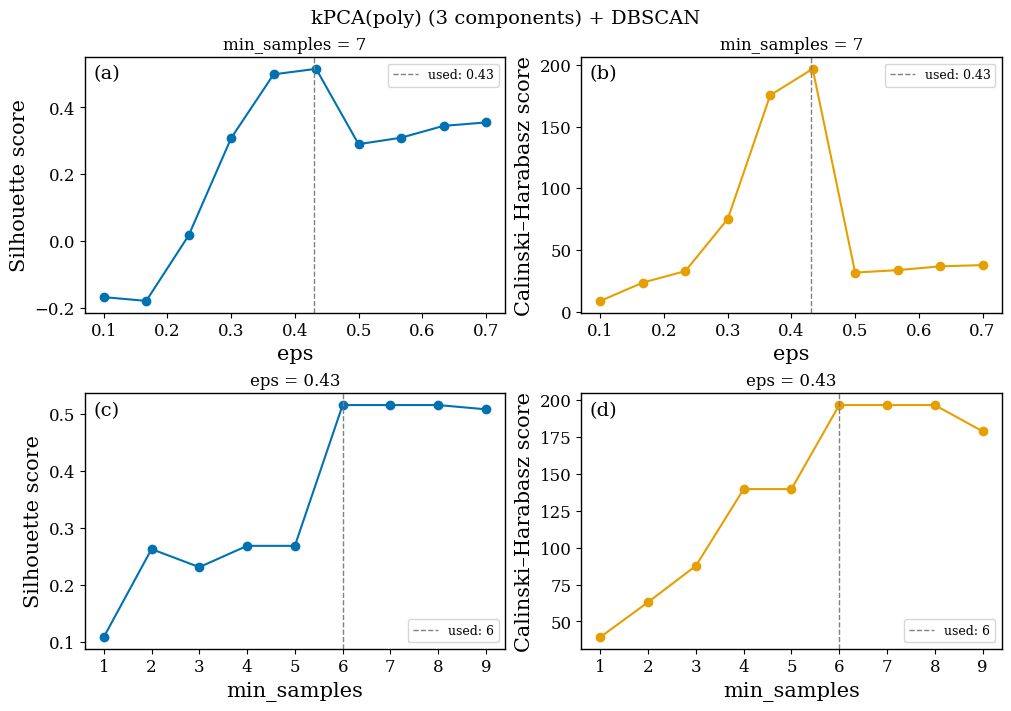

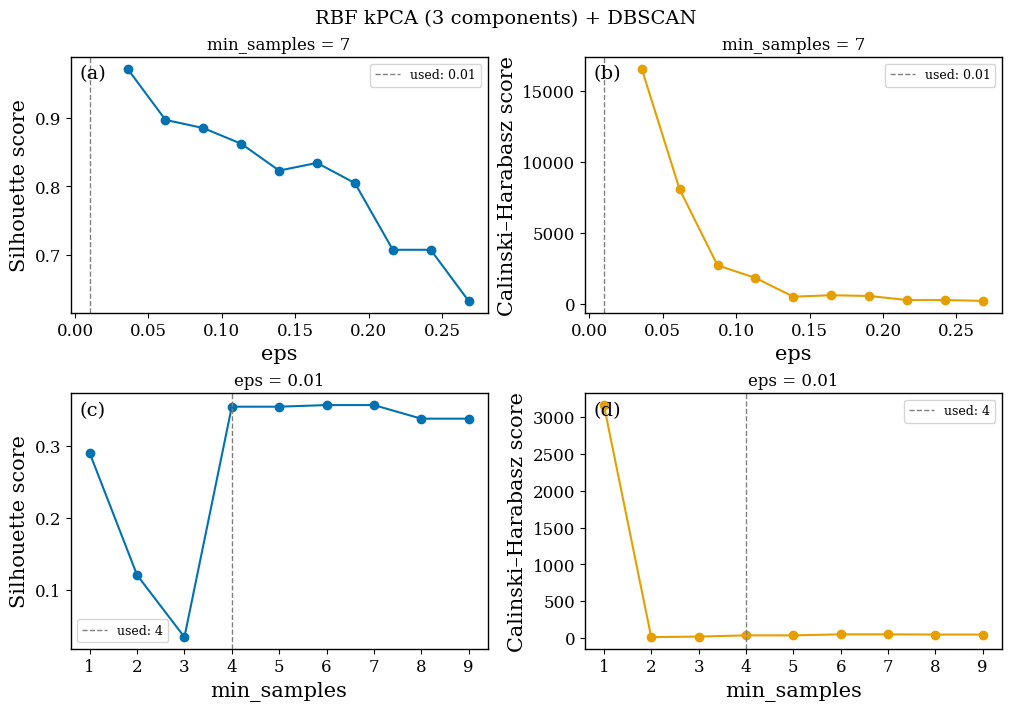

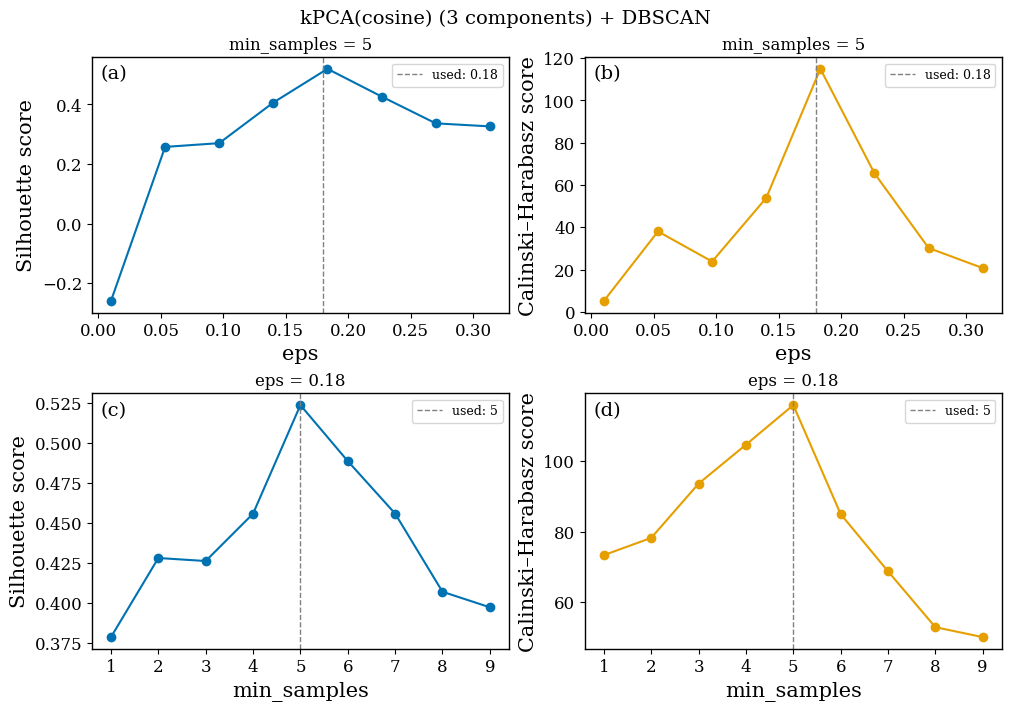

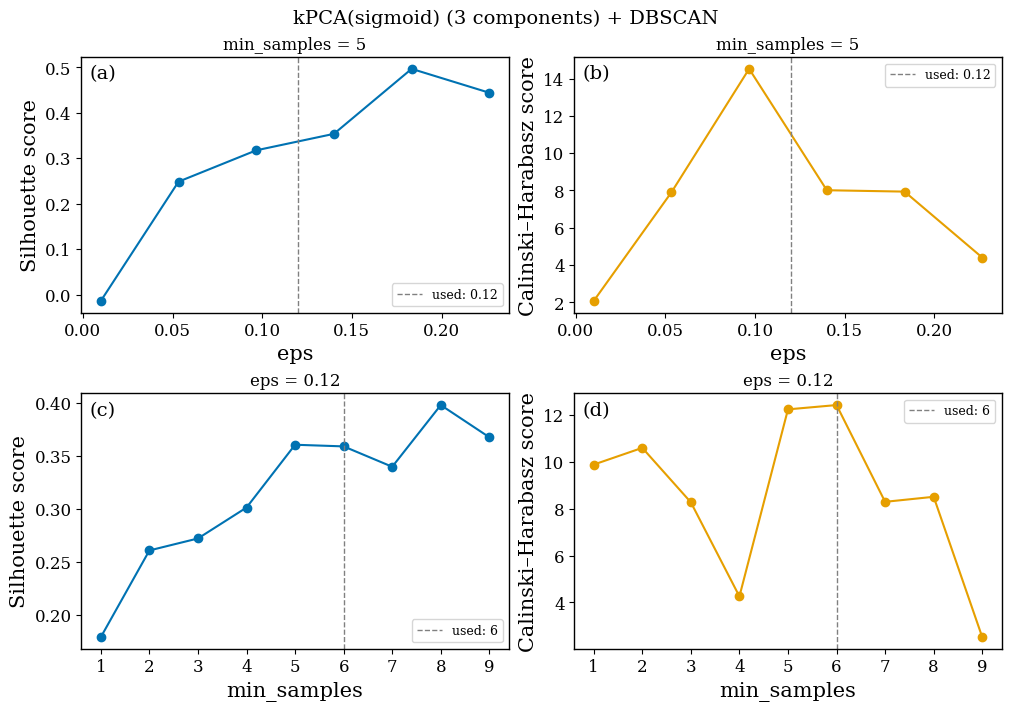

,Method,eps (Silhouette max),eps (CH max),min_samples (Silhouette max),min_samples (CH max),eps used,min_samples used
0,PCA,0.57,0.23,4,7,0.40,7
1,Incremental PCA,0.57,0.23,2,8,0.50,8
2,kPCA(poly),0.43,0.43,6,6,0.43,6
3,RBF kPCA,0.04,0.04,6,1,0.01,4
4,kPCA(cosine),0.18,0.18,5,5,0.18,5
5,kPCA(sigmoid),0.18,0.10,8,6,0.12,6


In [ ]:
# ==========================================================
# 5.2 RUN SWEEPS + SUPPORT FIGURES (one 2 × 2 figure per method)
# ==========================================================
sweep_summary = []

for sw in SWEEPS:

    X3 = sw["model"]().fit_transform(filtered_df)

    # --- eps sweep at fixed min_samples ---
    sil_eps, ch_eps = [], []
    for eps in sw["eps_range"]:
        lab = DBSCAN(eps=eps, min_samples=sw["eps_min_samples"]).fit_predict(X3)
        s, c = cluster_scores(X3, lab, drop_noise=sw["drop_noise_eps"])
        sil_eps.append(s)
        ch_eps.append(c)

    # --- min_samples sweep at fixed eps ---
    sil_min, ch_min = [], []
    for mins in MIN_RANGE:
        lab = DBSCAN(eps=sw["min_eps"], min_samples=mins).fit_predict(X3)
        s, c = cluster_scores(X3, lab)
        sil_min.append(s)
        ch_min.append(c)

    eps_sel, min_sel = SELECTED[sw["name"]]

    fig, axes = plt.subplots(2, 2, figsize=(10, 7), layout="constrained")

    panels = [
        (axes[0, 0], sw["eps_range"], sil_eps, "#0072B2", "eps", "Silhouette score",
         f'min_samples = {sw["eps_min_samples"]}', eps_sel),
        (axes[0, 1], sw["eps_range"], ch_eps, "#E69F00", "eps", "Calinski–Harabasz score",
         f'min_samples = {sw["eps_min_samples"]}', eps_sel),
        (axes[1, 0], MIN_RANGE, sil_min, "#0072B2", "min_samples", "Silhouette score",
         f'eps = {sw["min_eps"]}', min_sel),
        (axes[1, 1], MIN_RANGE, ch_min, "#E69F00", "min_samples", "Calinski–Harabasz score",
         f'eps = {sw["min_eps"]}', min_sel),
    ]

    for k, (ax, x, y, color, xlabel, ylabel, fixed, sel) in enumerate(panels):
        ax.plot(x, y, color=color, marker="o")
        ax.axvline(sel, color="grey", linestyle="--", linewidth=1.0,
                   label=f"used: {sel}")
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        ax.set_title(fixed, fontsize=12)
        ax.legend(loc="best", fontsize=9)
        ax.text(0.02, 0.97, f'({"abcd"[k]})', transform=ax.transAxes,
                va="top", **PANEL_KW)
        if xlabel == "min_samples":
            ax.xaxis.set_major_locator(MaxNLocator(integer=True))

    fig.suptitle(f'{sw["name"]} (3 components) + DBSCAN', fontsize=14)

    safe = re.sub(r"[^A-Za-z0-9]+", "_", sw["name"]).strip("_")
    fig.savefig(out(f"support_scores_{safe}.png"), dpi=300, bbox_inches="tight")
    plt.show()

    sweep_summary.append({
        "Method": sw["name"],
        "eps (Silhouette max)": round(float(best_of(sw["eps_range"], sil_eps)), 2),
        "eps (CH max)":         round(float(best_of(sw["eps_range"], ch_eps)), 2),
        "min_samples (Silhouette max)": best_of(MIN_RANGE, sil_min),
        "min_samples (CH max)":         best_of(MIN_RANGE, ch_min),
        "eps used": eps_sel,
        "min_samples used": min_sel,
    })

sweep_summary = pd.DataFrame(sweep_summary)
sweep_summary.to_csv(out("support_scores_optima.csv"), index=False)
display(sweep_summary)

## **6. DBSCAN clustering of the 2D projections (Figures 9–11)**

Same projections, hyperparameters, evaluated clusters and layout as the revised figures. The legend title of each method now reports three metrics for the evaluated cluster $C$, with $E$ the set of flare-interval measurements:

- **Coverage** (recall) $= |C \cap E| \, / \, |E|$, as before
- **Precision** $= |C \cap E| \, / \, |C|$, the fraction of the cluster that belongs to the flare interval
- **F1** $= 2PR/(P+R)$

A cluster that contains the whole dataset always reaches 100% coverage, while its precision falls to the event share of the data (printed in Section 1; 59.31% for 0.25–2.0 dB), which is the precision of a random grouping.

In [ ]:
# ==========================================================
# 6.1 METRICS
# ==========================================================
def cluster_metrics(labels, in_range_mask, cluster_id):
    """Coverage (recall), precision and F1 of one DBSCAN cluster
    with respect to the flare-interval measurements."""
    in_cluster = labels == cluster_id

    n_event      = int(np.sum(in_range_mask))
    n_cluster    = int(np.sum(in_cluster))
    n_event_in   = int(np.sum(in_cluster & in_range_mask))
    n_other_in   = n_cluster - n_event_in

    coverage  = n_event_in / n_event   if n_event   > 0 else 0.0
    precision = n_event_in / n_cluster if n_cluster > 0 else 0.0
    f1 = (2 * precision * coverage / (precision + coverage)
          if (precision + coverage) > 0 else 0.0)

    return {
        "cluster_size":  n_cluster,
        "event_in":      n_event_in,
        "other_in":      n_other_in,
        "coverage_pct":  100 * coverage,
        "precision_pct": 100 * precision,
        "f1":            f1,
    }

In [ ]:
# ==========================================================
# 6.2 METHOD PARAMETERS (UNCHANGED) + PROJECTIONS + CLUSTERS
# ==========================================================

# Original markers
markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']

# Event interval label (HH:MM, UTC)
event_label = r'$t\in [16{:}13,\ 16{:}40]\ \mathrm{UTC}$'

# Event mask on the filtered data
ids = filtered_df.index.values
in_range_mask = (
    (ids >= EVENT_ID_START) &
    (ids <= EVENT_ID_END)
)

methods = [
    {
        "name": "PCA",
        "projection_title": "PCA (2D)",
        "cluster_title": "DBSCAN Clusters (PCA)",
        "epsilon": 0.4,
        "min_samples": 7,
        "size": 20,
        "coverage_cluster": 1
    },
    {
        "name": "Incremental PCA",
        "projection_title": "Incremental PCA (2D)",
        "cluster_title": "DBSCAN Clusters (Incremental PCA)",
        "epsilon": 0.5,
        "min_samples": 8,
        "size": 15,
        "coverage_cluster": 1
    },
    {
        "name": "kPCA(poly)",
        "projection_title": "kPCA Poly (2D)",
        "cluster_title": "DBSCAN Clusters (Poly kPCA)",
        "epsilon": 0.43,
        "min_samples": 6,
        "size": 15,
        "coverage_cluster": 1
    },
    {
        "name": "RBF kPCA",
        "projection_title": "RBF kPCA (2D)",
        "cluster_title": "DBSCAN Clusters (RBF kPCA)",
        "epsilon": 0.01,
        "min_samples": 4,
        "size": 15,
        "coverage_cluster": 1
    },
    {
        "name": "kPCA(cosine)",
        "projection_title": "kPCA Cosine (2D)",
        "cluster_title": "DBSCAN Clusters (Cosine kPCA)",
        "epsilon": 0.18,
        "min_samples": 5,
        "size": 20,
        "coverage_cluster": 0
    },
    {
        "name": "kPCA(sigmoid)",
        "projection_title": "kPCA Sigmoid (2D)",
        "cluster_title": "DBSCAN Clusters (Sigmoid kPCA)",
        "epsilon": 0.12,
        "min_samples": 6,
        "size": 15,
        "coverage_cluster": 0
    }
]

results = []

for method in methods:

    name = method["name"]

    if name == "PCA":
        model = PCA(n_components=2)
        X_2d = model.fit_transform(filtered_df)

    elif name == "Incremental PCA":
        model = IncrementalPCA(n_components=2)
        X_2d = model.fit_transform(filtered_df)

    elif name == "kPCA(poly)":
        model = KernelPCA(n_components=2, kernel="poly")
        X_2d = model.fit_transform(filtered_df)

    elif name == "RBF kPCA":
        model = KernelPCA(n_components=2, kernel="rbf", gamma=1)
        X_scaled = StandardScaler().fit_transform(filtered_df)
        X_2d = model.fit_transform(X_scaled)

    elif name == "kPCA(cosine)":
        model = KernelPCA(n_components=2, kernel="cosine")
        X_2d = model.fit_transform(filtered_df)

    elif name == "kPCA(sigmoid)":
        model = KernelPCA(n_components=2, kernel="sigmoid")
        X_2d = model.fit_transform(filtered_df)

    dbscan = DBSCAN(
        eps=method["epsilon"],
        min_samples=method["min_samples"]
    )
    labels = dbscan.fit_predict(X_2d)

    metrics = cluster_metrics(labels, in_range_mask, method["coverage_cluster"])

    results.append({
        "X_2d": X_2d,
        "labels": labels,
        "n_clusters": int(len(set(labels)) - (1 if -1 in labels else 0)),
        "n_noise": int(np.sum(labels == -1)),
        **metrics,
    })

# Quick check
for method, r in zip(methods, results):
    print(f'{method["name"]:16s} cluster {method["coverage_cluster"]}: '
          f'coverage {r["coverage_pct"]:6.2f}%  precision {r["precision_pct"]:6.2f}%  '
          f'F1 {r["f1"]:.3f}  (size {r["cluster_size"]}: {r["event_in"]} event, {r["other_in"]} other)')

PCA              cluster 1: coverage  72.73%  precision 100.00%  F1 0.842  (size 88: 88 event, 0 other)
Incremental PCA  cluster 1: coverage  74.38%  precision  98.90%  F1 0.849  (size 91: 90 event, 1 other)
kPCA(poly)       cluster 1: coverage  40.50%  precision 100.00%  F1 0.576  (size 49: 49 event, 0 other)
RBF kPCA         cluster 1: coverage  31.40%  precision  34.86%  F1 0.330  (size 109: 38 event, 71 other)
kPCA(cosine)     cluster 0: coverage  85.95%  precision  65.82%  F1 0.746  (size 158: 104 event, 54 other)
kPCA(sigmoid)    cluster 0: coverage  91.74%  precision  59.36%  F1 0.721  (size 187: 111 event, 76 other)


In [ ]:
# ==========================================================
# 6.2b PC1 vs ABSORPTION LEVEL (Spearman) + PC1 LOADINGS
# ==========================================================
from scipy.stats import spearmanr

# Beam-averaged CNA of every filtered measurement [dB]
mean_cna = filtered_df.mean(axis=1).to_numpy()

# --- Spearman correlation between PC1 and the beam-averaged CNA ---
# (the sign of a principal component is arbitrary: read |rho|)
rows = []
for method, r in zip(methods, results):
    pc1 = r["X_2d"][:, 0]
    rho_all = spearmanr(pc1, mean_cna).correlation
    rho_evt = spearmanr(pc1[in_range_mask], mean_cna[in_range_mask]).correlation
    rows.append({
        "Method": method["name"],
        "Spearman PC1 vs CNA (all)": round(rho_all, 2),
        "Spearman PC1 vs CNA (flare interval)": round(rho_evt, 2),
    })

spearman_table = pd.DataFrame(rows)
spearman_table.to_csv(out("pc1_spearman.csv"), index=False)
display(spearman_table)

# --- PC1 loadings (beam weights) of the linear methods ---
loadings = pd.DataFrame(
    {
        "PCA":  PCA(n_components=2).fit(filtered_df).components_[0],
        "IPCA": IncrementalPCA(n_components=2).fit(filtered_df).components_[0],
    },
    index=filtered_df.columns,
).round(3)

loadings.to_csv(out("pc1_loadings.csv"))
display(loadings.T)

for col in loadings.columns:
    n_pos = int((loadings[col] > 0).sum())
    print(f"{col}: {n_pos} of {len(loadings)} PC1 loadings are positive")

# --- Mean CNA of the flare measurements inside / outside the evaluated cluster ---
for method, r in zip(methods, results):
    in_cl = (r["labels"] == method["coverage_cluster"]) & in_range_mask
    out_cl = (r["labels"] != method["coverage_cluster"]) & in_range_mask
    txt_in = f"{mean_cna[in_cl].mean():.2f} dB" if in_cl.any() else "none"
    txt_out = f"{mean_cna[out_cl].mean():.2f} dB" if out_cl.any() else "none (all in cluster)"
    print(f'{method["name"]:16s} flare measurements in cluster {method["coverage_cluster"]}: '
          f'mean CNA {txt_in} | not in cluster: {txt_out}')


,Method,Spearman PC1 vs CNA (all),Spearman PC1 vs CNA (flare interval)
0,PCA,0.93,0.94
1,Incremental PCA,0.94,0.95
2,kPCA(poly),0.98,1.00
3,RBF kPCA,0.54,0.76
4,kPCA(cosine),-0.33,0.14
5,kPCA(sigmoid),-0.16,0.20


,Beam 1,Beam 2,Beam 3,Beam 4,Beam 5,Beam 6,Beam 7,Beam 8,Beam 9,Beam 10,Beam 11,Beam 12,Beam 13,Beam 14,Beam 15,Beam 16
PCA,0.144,0.250,0.309,0.173,-0.067,0.172,0.167,0.061,0.277,0.150,0.250,0.403,0.235,0.249,0.384,0.371
IPCA,0.165,0.253,0.319,0.151,-0.037,0.177,0.169,0.048,0.280,0.154,0.245,0.401,0.234,0.252,0.389,0.358


PCA: 15 of 16 PC1 loadings are positive
IPCA: 15 of 16 PC1 loadings are positive
PCA              flare measurements in cluster 1: mean CNA 1.13 dB | not in cluster: 0.61 dB
Incremental PCA  flare measurements in cluster 1: mean CNA 1.11 dB | not in cluster: 0.62 dB
kPCA(poly)       flare measurements in cluster 1: mean CNA 1.37 dB | not in cluster: 0.73 dB
RBF kPCA         flare measurements in cluster 1: mean CNA 0.71 dB | not in cluster: 1.11 dB
kPCA(cosine)     flare measurements in cluster 0: mean CNA 1.04 dB | not in cluster: 0.66 dB
kPCA(sigmoid)    flare measurements in cluster 0: mean CNA 1.02 dB | not in cluster: 0.58 dB


In [ ]:
# ==========================================================
# 6.3 LAYOUT (UNCHANGED)
# ==========================================================
PAGE_WIDTH_IN = 7.0           # full page width (check journal)

PLOT_HEIGHT_IN = 2.2
PLOT_LEGEND_GAP_IN = 0.55     # room for x tick labels and "PC 1"
BETWEEN_ROWS_IN = 0.30
TOP_IN = 0.35                 # room for panel titles
BOTTOM_LEGEND_IN = 0.45       # shared legend for the left panels

LEGEND_FONTSIZE = 9
LEGEND_LINE_HEIGHT_IN = 0.175
LEGEND_PADDING_IN = 0.25

LEFT_MARGIN = 0.10
RIGHT_MARGIN = 0.03
COLUMN_GAP = 0.10

column_width = (1.0 - LEFT_MARGIN - RIGHT_MARGIN - COLUMN_GAP) / 2

left_positions = [
    LEFT_MARGIN,
    LEFT_MARGIN + column_width + COLUMN_GAP
]


def legend_height_for(labels):
    """Height (in) of a 2-column legend for one method.

    Two columns -> one legend row per cluster
    (in range | not in range), plus 3 title lines.
    """
    n_clusters = len(np.unique(labels))
    n_lines = n_clusters + 3
    return n_lines * LEGEND_LINE_HEIGHT_IN + LEGEND_PADDING_IN


def legend_title(method, result):
    """DBSCAN information shown as the legend title (now with precision and F1)."""
    return (
        f'{method["name"]} + DBSCAN  |  '
        f'eps = {method["epsilon"]}  |  '
        f'min = {method["min_samples"]}\n'
        f'Cluster {method["coverage_cluster"]}:  '
        f'coverage = {result["coverage_pct"]:.2f}%  |  '
        f'precision = {result["precision_pct"]:.2f}%  |  '
        f'F1 = {result["f1"]:.3f}'
    )

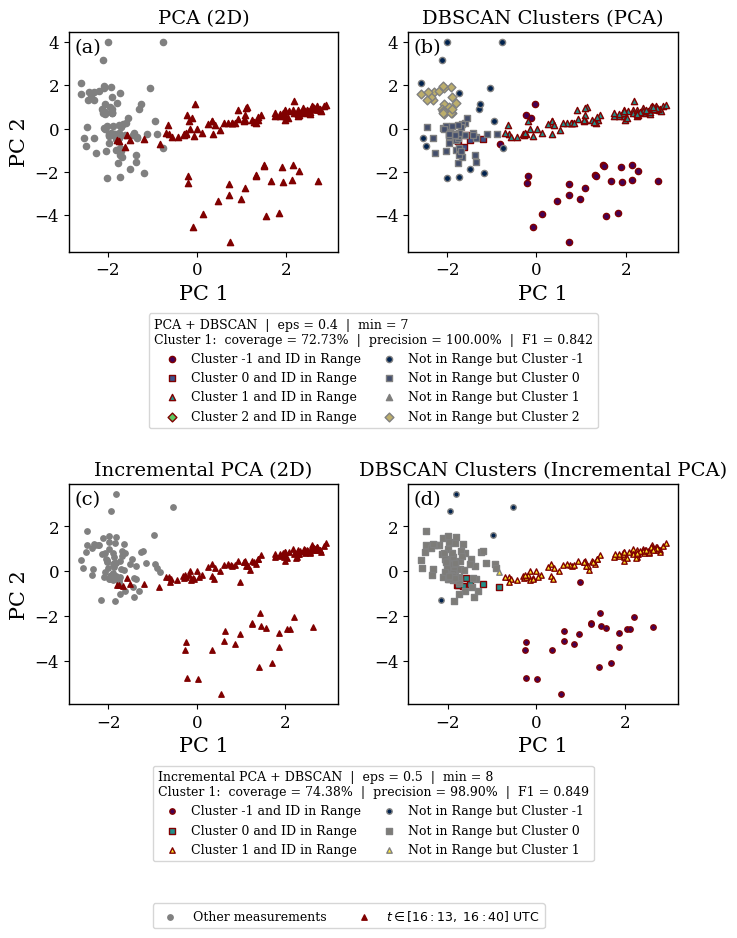

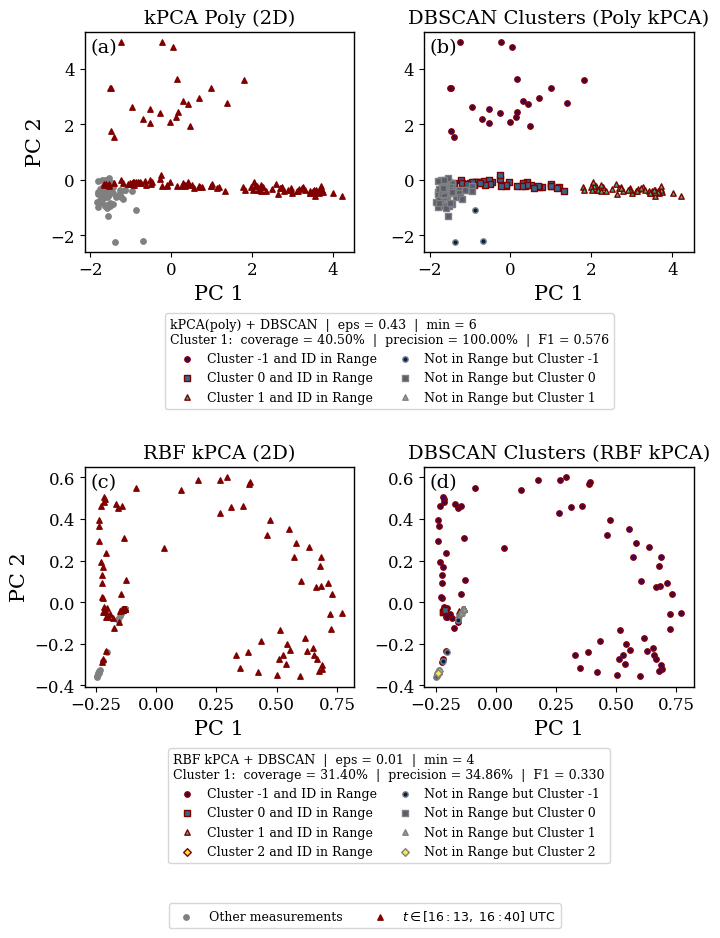

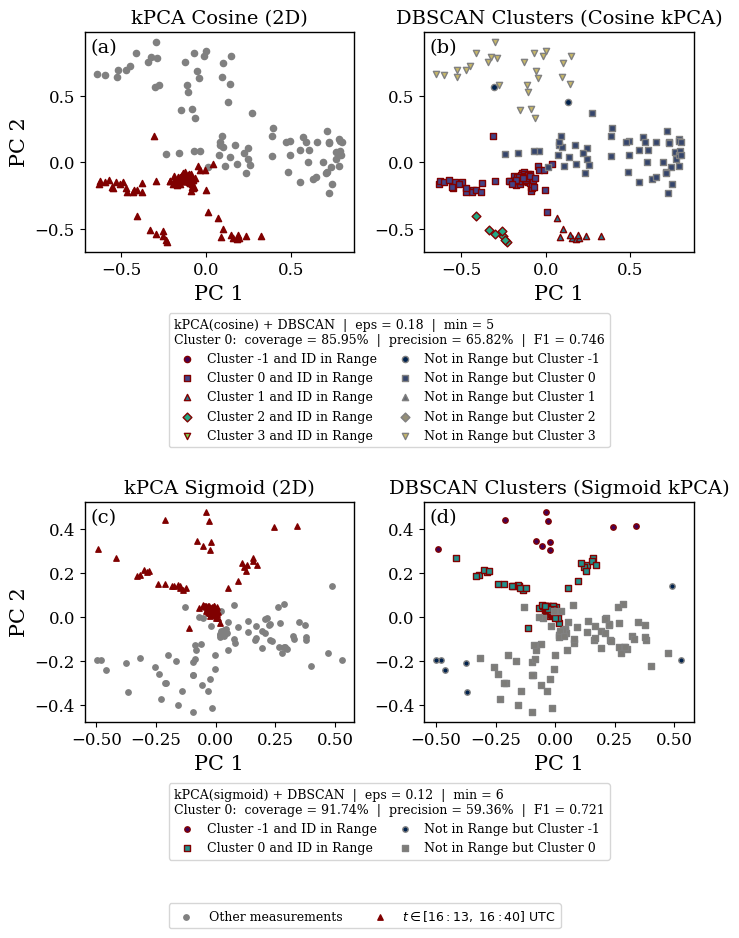

In [ ]:
# ==========================================================
# 6.4 ONE FIGURE = 2 METHODS (2 ROWS × 2 PANELS)
# ==========================================================
def plot_group(group, filename):

    leg_heights = [legend_height_for(result["labels"]) for _, result in group]

    total_height = (
        TOP_IN
        + sum(PLOT_HEIGHT_IN + PLOT_LEGEND_GAP_IN + h for h in leg_heights)
        + BETWEEN_ROWS_IN * (len(group) - 1)
        + BOTTOM_LEGEND_IN
    )

    fig = plt.figure(figsize=(PAGE_WIDTH_IN, total_height))

    letters = 'abcdefgh'
    current_y_in = total_height - TOP_IN

    for row, ((method, result), leg_h) in enumerate(zip(group, leg_heights)):

        X_2d = result["X_2d"]
        labels = result["labels"]
        point_size = method["size"]

        # ---------------- positions (inches -> figure fraction) ----------------
        plot_bottom_in = current_y_in - PLOT_HEIGHT_IN
        legend_bottom_in = plot_bottom_in - PLOT_LEGEND_GAP_IN - leg_h

        ax1 = fig.add_axes([
            left_positions[0],
            plot_bottom_in / total_height,
            column_width,
            PLOT_HEIGHT_IN / total_height
        ])

        ax2 = fig.add_axes([
            left_positions[1],
            plot_bottom_in / total_height,
            column_width,
            PLOT_HEIGHT_IN / total_height
        ], sharex=ax1, sharey=ax1)

        # Legend area spans the full width under the row
        leg_ax = fig.add_axes([
            LEFT_MARGIN,
            legend_bottom_in / total_height,
            1 - LEFT_MARGIN - RIGHT_MARGIN,
            leg_h / total_height
        ])
        leg_ax.axis("off")

        # ---------------- LEFT — 2D projection ----------------
        ax1.scatter(X_2d[~in_range_mask, 0], X_2d[~in_range_mask, 1],
                    label="Other measurements", color="grey", s=point_size)
        ax1.scatter(X_2d[in_range_mask, 0], X_2d[in_range_mask, 1],
                    label=event_label, color="maroon", marker="^", s=point_size)

        ax1.set_xlabel("PC 1")
        ax1.set_ylabel("PC 2")
        ax1.set_title(method["projection_title"])

        # ---------------- RIGHT — DBSCAN clusters ----------------
        unique_clusters = np.unique(labels)

        if method["name"] in ["Incremental PCA", "RBF kPCA"]:
            n_colors = len(unique_clusters)
        else:
            n_colors = len(unique_clusters) + 1

        colors_out = cm.cividis(np.linspace(0, 1, n_colors))
        colors_in = cm.viridis(np.linspace(0, 1, n_colors))

        # In-range points (first legend column)
        for idx, cluster_id in enumerate(unique_clusters):
            mask_in = (labels == cluster_id) & in_range_mask
            ax2.scatter(X_2d[mask_in, 0], X_2d[mask_in, 1],
                        label=f"Cluster {cluster_id} and ID in Range",
                        color=colors_in[idx],
                        marker=markers[idx % len(markers)],
                        edgecolors="maroon", s=point_size)

        # Out-of-range points (second legend column)
        for idx, cluster_id in enumerate(unique_clusters):
            mask_out = (labels == cluster_id) & ~in_range_mask
            ax2.scatter(X_2d[mask_out, 0], X_2d[mask_out, 1],
                        label=f"Not in Range but Cluster {cluster_id}",
                        color=colors_out[idx],
                        marker=markers[idx % len(markers)],
                        edgecolors="gray", s=point_size)

        ax2.set_xlabel("PC 1")
        ax2.set_title(method["cluster_title"])

        # ---------------- right legend below the row, 2 columns ----------------
        handles2, labels2 = ax2.get_legend_handles_labels()

        leg_ax.legend(
            handles2, labels2,
            loc="upper center", bbox_to_anchor=(0.5, 1.0),
            ncol=2, frameon=True,
            fontsize=LEGEND_FONTSIZE,
            title=legend_title(method, result),
            title_fontsize=LEGEND_FONTSIZE,
            handlelength=1.5, columnspacing=1.5
        )

        # ---------------- panel letters ----------------
        for j, ax in enumerate((ax1, ax2)):
            ax.text(0.02, 0.97, f'({letters[2 * row + j]})',
                    transform=ax.transAxes, va='top', **PANEL_KW)

        current_y_in = legend_bottom_in - BETWEEN_ROWS_IN

    # ---------------- shared legend for the left panels ----------------
    handles1, labels1 = ax1.get_legend_handles_labels()
    fig.legend(handles1, labels1,
               loc="lower center", bbox_to_anchor=(0.5, 0.0),
               ncol=2, frameon=True, fontsize=LEGEND_FONTSIZE)

    fig.savefig(filename, dpi=600, bbox_inches="tight")
    plt.show()


# ==========================================================
# 6.5 THREE FIGURES, TWO METHODS EACH
# ==========================================================
groups = [
    (0, 2, "pca_ipca_dbscan.png"),          # \label{fig:pca_ipca_dbscan}
    (2, 4, "kpca_poly_rbf_dbscan.png"),     # \label{fig:kpca_poly_rbf_dbscan}
    (4, 6, "kpca_cos_sigmoid_dbscan.png"),  # \label{fig:kpca_cos_sigmoid_dbscan}
]

for start, end, fname in groups:
    plot_group(list(zip(methods[start:end], results[start:end])), out(fname))

## **7. Metrics table (for the manuscript)**

Saved as `figures_master/dbscan_metrics.csv` and printed as LaTeX rows.

In [ ]:
table = pd.DataFrame([{
    "Method":        m["name"],
    "eps":           m["epsilon"],
    "min_samples":   m["min_samples"],
    "Clusters":      r["n_clusters"],
    "Noise":         r["n_noise"],
    "Cluster":       m["coverage_cluster"],
    "Size":          r["cluster_size"],
    "Event in":      r["event_in"],
    "Other in":      r["other_in"],
    "Coverage (%)":  round(r["coverage_pct"], 2),
    "Precision (%)": round(r["precision_pct"], 2),
    "F1":            round(r["f1"], 3),
} for m, r in zip(methods, results)])

table.to_csv(out("dbscan_metrics.csv"), index=False)

print(f"Dataset: {N_TOTAL} measurements ({N_EVENT} flare interval, {N_OTHER} other); "
      f"random-grouping precision = {100*BASE_RATE:.2f}%\n")
display(table)

LATEX_NAMES = {
    "PCA": "PCA", "Incremental PCA": "IPCA", "kPCA(poly)": "k-PCA (polynomial)",
    "RBF kPCA": "k-PCA (RBF)", "kPCA(cosine)": "k-PCA (cosine)",
    "kPCA(sigmoid)": "k-PCA (sigmoid)",
}

print("\nMethod & $\\varepsilon$ & min\\_samples & Cluster & Size & Coverage (\\%) & Precision (\\%) & $F_1$ \\\\")
for _, row in table.iterrows():
    print(f'{LATEX_NAMES[row["Method"]]} & {row["eps"]} & {row["min_samples"]} & '
          f'{row["Cluster"]} & {row["Size"]} & {row["Coverage (%)"]:.2f} & '
          f'{row["Precision (%)"]:.2f} & {row["F1"]:.3f} \\\\')

Dataset: 204 measurements (121 flare interval, 83 other); random-grouping precision = 59.31%



,Method,eps,min_samples,Clusters,Noise,Cluster,Size,Event in,Other in,Coverage (%),Precision (%),F1
0,PCA,0.40,7,3,43,1,88,88,0,72.73,100.00,0.842
1,Incremental PCA,0.50,8,2,29,1,91,90,1,74.38,98.90,0.849
2,kPCA(poly),0.43,6,2,26,1,49,49,0,40.50,100.00,0.576
3,RBF kPCA,0.01,4,3,87,1,109,38,71,31.40,34.86,0.330
4,kPCA(cosine),0.18,5,4,2,0,158,104,54,85.95,65.82,0.746
5,kPCA(sigmoid),0.12,6,1,17,0,187,111,76,91.74,59.36,0.721



Method & $\varepsilon$ & min\_samples & Cluster & Size & Coverage (\%) & Precision (\%) & $F_1$ \\
PCA & 0.4 & 7 & 1 & 88 & 72.73 & 100.00 & 0.842 \\
IPCA & 0.5 & 8 & 1 & 91 & 74.38 & 98.90 & 0.849 \\
k-PCA (polynomial) & 0.43 & 6 & 1 & 49 & 40.50 & 100.00 & 0.576 \\
k-PCA (RBF) & 0.01 & 4 & 1 & 109 & 31.40 & 34.86 & 0.330 \\
k-PCA (cosine) & 0.18 & 5 & 0 & 158 & 85.95 & 65.82 & 0.746 \\
k-PCA (sigmoid) & 0.12 & 6 & 0 & 187 & 91.74 & 59.36 & 0.721 \\


In [ ]:
# ==========================================================
# OPTIONAL — download every output as one zip (Colab)
# ==========================================================
zip_name = "figures_master.zip"
with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zf:
    for f in sorted(os.listdir(OUTDIR)):
        zf.write(os.path.join(OUTDIR, f), arcname=f)
print(f"{len(os.listdir(OUTDIR))} files in {zip_name}:")
for f in sorted(os.listdir(OUTDIR)):
    print("  ", f)

try:
    from google.colab import files
    files.download(zip_name)
except ImportError:
    pass

17 files in figures_master.zip:
   1103_TRW_PCA_variants.jpg
   1103_TRW_combined_trustworthiness.png
   Figure_1_TRW_GOES_revised.pdf
   Figure_1_TRW_GOES_revised.png
   dbscan_metrics.csv
   kpca_cos_sigmoid_dbscan.png
   kpca_poly_rbf_dbscan.png
   pc1_loadings.csv
   pc1_spearman.csv
   pca_ipca_dbscan.png
   support_scores_Incremental_PCA.png
   support_scores_PCA.png
   support_scores_RBF_kPCA.png
   support_scores_kPCA_cosine.png
   support_scores_kPCA_poly.png
   support_scores_kPCA_sigmoid.png
   support_scores_optima.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>